#1.0 Data Preprocessing

##1.1 Import Libraries

In [ ]:
import os
import gdown
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

##1.2 Download Dataset

In [ ]:
file_id = "1H3pd2cVZttf9_PapHCKi3E9EI4lVczCv"
output = "dataset.csv"

if not os.path.exists(output):
    gdown.download(
        f"https://drive.google.com/uc?id={file_id}",
        output,
        quiet=True
    )
print("Dataset is successfully downloaded")

Dataset is successfully downloaded


##1.3 Load Dataset

In [ ]:
df = pd.read_csv(output)
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"\nColumns: {list(df.columns)}")
df.head(5)

Dataset shape: 5000 rows × 10 columns

Columns: ['Temperature', 'Humidity', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'Proximity_to_Industrial_Areas', 'Population_Density', 'Air Quality']


,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality
0,29.8,59.1,5.2,17.9,18.9,9.2,1.72,6.3,319,Moderate
1,28.3,75.6,2.3,12.2,30.8,9.7,1.64,6.0,611,Moderate
2,23.1,74.7,26.7,33.8,24.4,12.6,1.63,5.2,619,Moderate
3,27.1,39.1,6.1,6.3,13.5,5.3,1.15,11.1,551,Good
4,26.5,70.7,6.9,16.0,21.9,5.6,1.01,12.7,303,Good


##1.4 Data Types & Descriptive Statistics

In [ ]:
print("=== DATA TYPES & NON-NULL COUNTS ===")
df.info()
print("\n=== DESCRIPTIVE STATISTICS ===")
df.describe().round(2)

=== DATA TYPES & NON-NULL COUNTS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Temperature                    5000 non-null   float64
 1   Humidity                       5000 non-null   float64
 2   PM2.5                          5000 non-null   float64
 3   PM10                           5000 non-null   float64
 4   NO2                            5000 non-null   float64
 5   SO2                            5000 non-null   float64
 6   CO                             5000 non-null   float64
 7   Proximity_to_Industrial_Areas  5000 non-null   float64
 8   Population_Density             5000 non-null   int64  
 9   Air Quality                    5000 non-null   object 
dtypes: float64(8), int64(1), object(1)
memory usage: 390.8+ KB

=== DESCRIPTIVE STATISTICS ===


,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,30.03,70.06,20.14,30.22,26.41,10.01,1.50,8.43,497.42
std,6.72,15.86,24.55,27.35,8.90,6.75,0.55,3.61,152.75
min,13.40,36.00,0.00,-0.20,7.40,-6.20,0.65,2.50,188.00
25%,25.10,58.30,4.60,12.30,20.10,5.10,1.03,5.40,381.00
50%,29.00,69.80,12.00,21.70,25.30,8.00,1.41,7.90,494.00
75%,34.00,80.30,26.10,38.10,31.90,13.72,1.84,11.10,600.00
max,58.60,128.10,295.00,315.80,64.90,44.90,3.72,25.80,957.00


##1.5 Handling Missing Values & Duplicates

In [ ]:
missing= df.isnull().sum()
missing_pct= (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %'    : missing_pct
})

print("=== MISSING VALUES PER COLUMN ===")
print(missing_df)

if missing.sum() == 0:
    print("\n✓ No missing values found!")
else:
    print(f"\n⚠ Total missing cells: {missing.sum()}")

dupes = df.duplicated().sum()
if dupes == 0:
    print("\n✓ No duplicate data found!")
else:
    print(f"\n⚠ Total duplicates: {dupes}")

=== MISSING VALUES PER COLUMN ===
                               Missing Count  Missing %
Temperature                                0        0.0
Humidity                                   0        0.0
PM2.5                                      0        0.0
PM10                                       0        0.0
NO2                                        0        0.0
SO2                                        0        0.0
CO                                         0        0.0
Proximity_to_Industrial_Areas              0        0.0
Population_Density                         0        0.0
Air Quality                                0        0.0

✓ No missing values found!

✓ No duplicate data found!


## 1.6 Target Class Distribution

=== TARGET CLASS DISTRIBUTION ===
  Good        :  2000 samples (40.0%)
  Moderate    :  1500 samples (30.0%)
  Poor        :  1000 samples (20.0%)
  Hazardous   :   500 samples (10.0%)


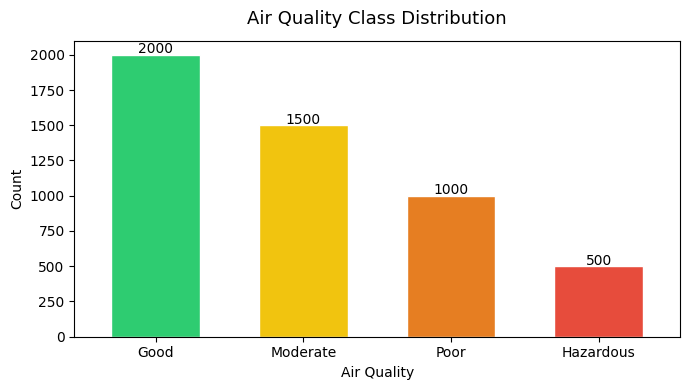

In [ ]:
TARGET = 'Air Quality'

counts = df[TARGET].value_counts()
pcts   = df[TARGET].value_counts(normalize=True) * 100

print("=== TARGET CLASS DISTRIBUTION ===")
for cls, cnt in counts.items():
    print(f"  {cls:12s}: {cnt:5d} samples ({pcts[cls]:.1f}%)")

colors = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c']
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot(kind='bar', ax=ax, color=colors, edgecolor='white', width=0.6)
ax.set_title('Air Quality Class Distribution', fontsize=13, pad=12)
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=0)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2, p.get_height() + 10),
                ha='center', fontsize=10)
plt.tight_layout()
plt.show()

## 1.7 Feature Distributions

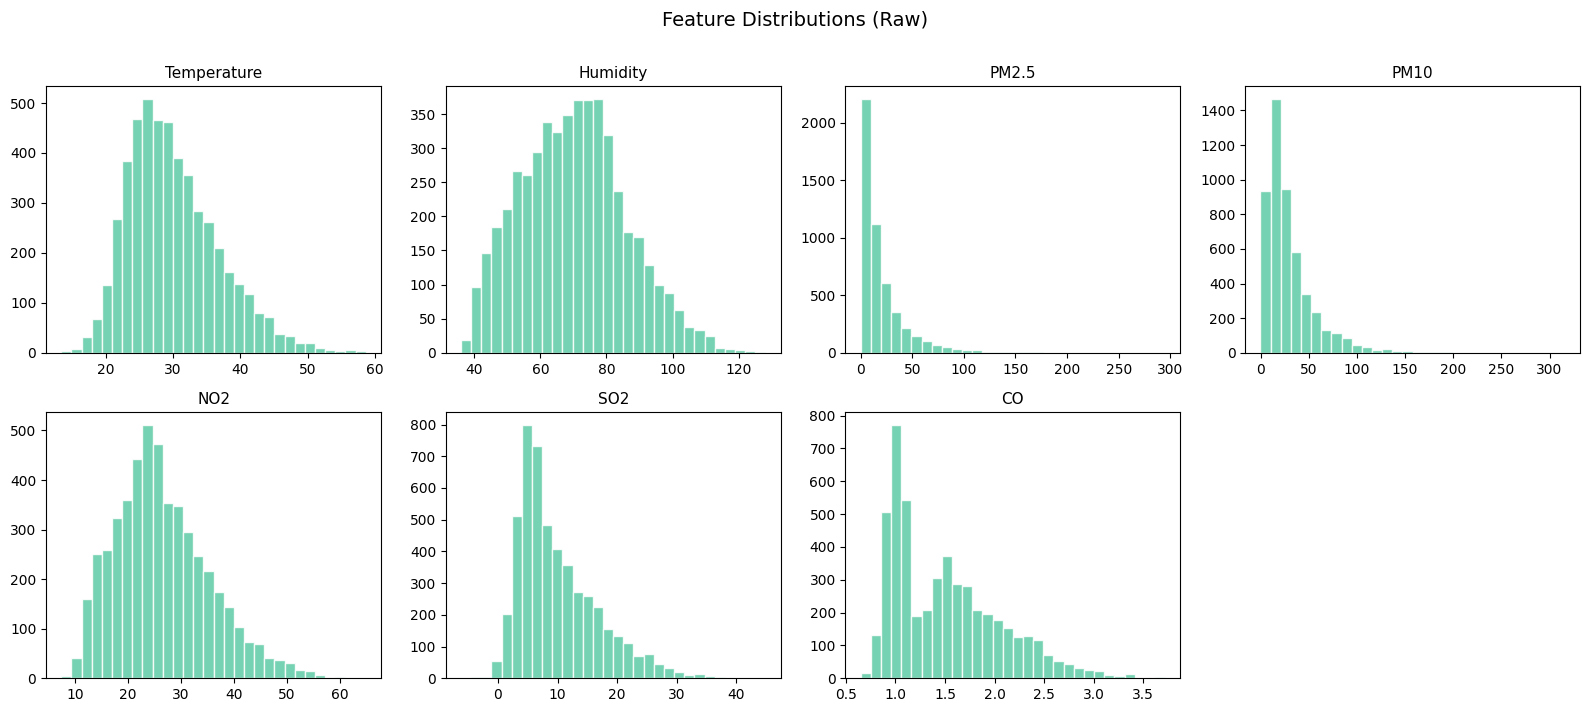

In [ ]:
FEATURES = ['Temperature', 'Humidity', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO']

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for i, col in enumerate(FEATURES):
    axes[i].hist(df[col].dropna(), bins=30,
                 color='#5DCAA5', edgecolor='white', alpha=0.85)
    axes[i].set_title(col, fontsize=11)

axes[-1].axis('off')
plt.suptitle('Feature Distributions (Raw)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

##1.8 Correlation Heatmap

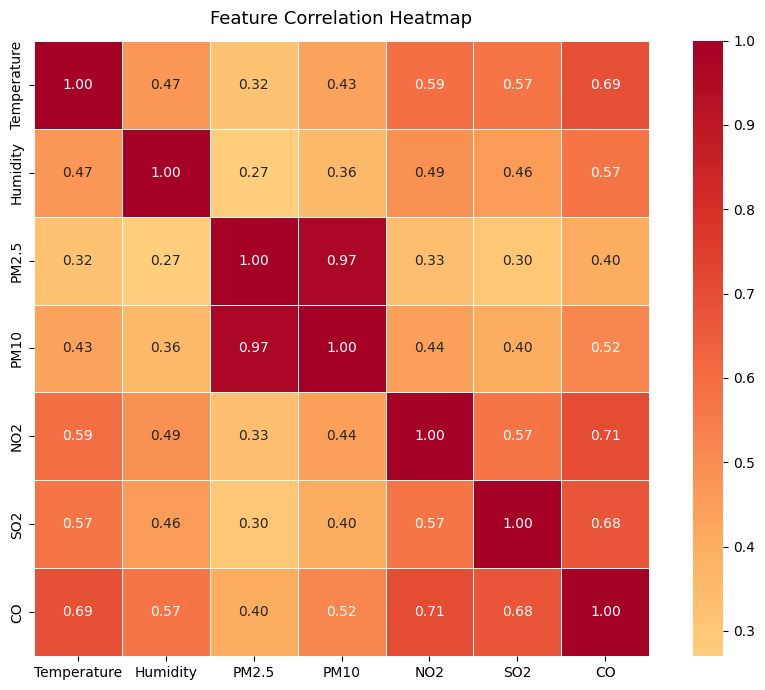

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[FEATURES].corr().round(2),
            annot=True, fmt='.2f',
            cmap='RdYlGn_r', center=0,
            square=True, linewidths=0.5, ax=ax)
ax.set_title('Feature Correlation Heatmap', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

##1.9 Boxplot (Air Quality Class)

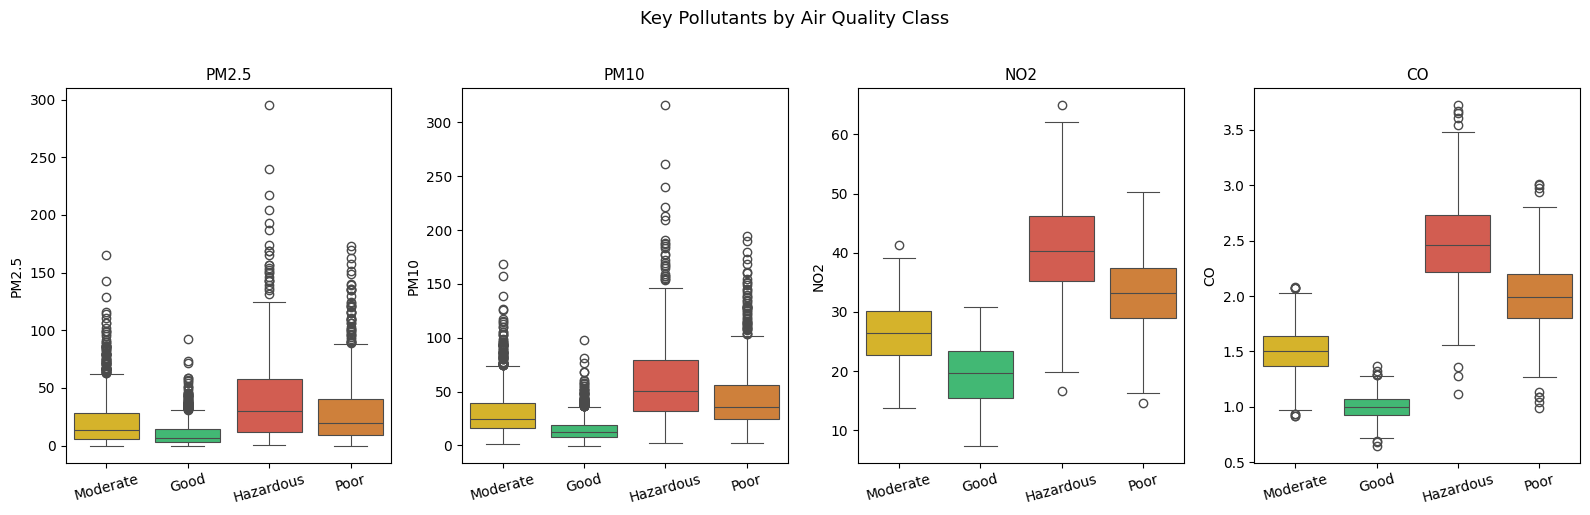

In [ ]:
KEY_FEATURES = ['PM2.5', 'PM10', 'NO2', 'CO']
palette = {'Good': '#2ecc71', 'Moderate': '#f1c40f',
           'Poor': '#e67e22',  'Hazardous': '#e74c3c'}

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, feat in zip(axes, KEY_FEATURES):
    sns.boxplot(data=df, x=TARGET, y=feat,
                hue=TARGET,
                palette=palette,
                legend=False,
                ax=ax, linewidth=0.8)
    ax.set_title(feat, fontsize=11)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=15)

plt.suptitle('Key Pollutants by Air Quality Class', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

##1.10 EDA Summary

In [ ]:
print("========== EDA SUMMARY ==========")
print(f"Total samples  : {len(df)}")
print(f"Total features : {len(FEATURES)}")
print(f"Missing values : {df.isnull().sum().sum()}")
print(f"Duplicate rows : {df.duplicated().sum()}")
print(f"\nClass distribution:")
for cls, cnt in df[TARGET].value_counts().items():
    print(f"  {cls}: {cnt} ({cnt/len(df)*100:.1f}%)")
print("\nFeature ranges:")
for f in FEATURES:
    print(f"  {f:15s}: min={df[f].min():.2f}, max={df[f].max():.2f}, mean={df[f].mean():.2f}")
print("=================================")

========== EDA SUMMARY ==========
Total samples  : 5000
Total features : 7
Missing values : 0
Duplicate rows : 0

Class distribution:
  Good: 2000 (40.0%)
  Moderate: 1500 (30.0%)
  Poor: 1000 (20.0%)
  Hazardous: 500 (10.0%)

Feature ranges:
  Temperature    : min=13.40, max=58.60, mean=30.03
  Humidity       : min=36.00, max=128.10, mean=70.06
  PM2.5          : min=0.00, max=295.00, mean=20.14
  PM10           : min=-0.20, max=315.80, mean=30.22
  NO2            : min=7.40, max=64.90, mean=26.41
  SO2            : min=-6.20, max=44.90, mean=10.01
  CO             : min=0.65, max=3.72, mean=1.50


##1.11 Data Cleaning (Invalid Values)

=== ANOMALIES DETECTED ===
  Humidity > 100      : 195 rows
  PM2.5 < 0           : 0 rows
  PM10 < 0            : 1 rows
  NO2 < 0             : 0 rows
  SO2 < 0             : 30 rows
  CO < 0              : 0 rows

=== AFTER CLEANING ===
  Humidity max : 100.00  (was 128.10)
  PM2.5 min    : 0.00
  PM10 min     : 0.00
✓ Rows kept   : 5000 / 5000


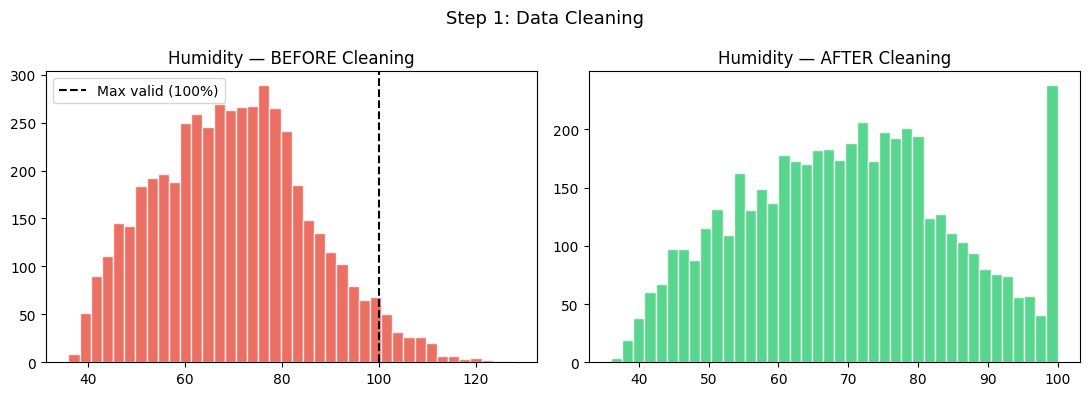

In [ ]:
df_clean = df.copy()
checks = {
    'Humidity > 100' : ('Humidity', 'upper', 100.0),
    'PM2.5 < 0'      : ('PM2.5',    'lower', 0.0),
    'PM10 < 0'       : ('PM10',     'lower', 0.0),
    'NO2 < 0'        : ('NO2',      'lower', 0.0),
    'SO2 < 0'        : ('SO2',      'lower', 0.0),
    'CO < 0'         : ('CO',       'lower', 0.0),
}

print("=== ANOMALIES DETECTED ===")
for label, (col, direction, val) in checks.items():
    if direction == 'upper':
        count = (df_clean[col] > val).sum()
    else:
        count = (df_clean[col] < val).sum()
    print(f"  {label:20s}: {count} rows")

df_clean['Humidity'] = df_clean['Humidity'].clip(upper=100.0)
for col in ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO']:
    df_clean[col] = df_clean[col].clip(lower=0.0)

print("\n=== AFTER CLEANING ===")
print(f"  Humidity max : {df_clean['Humidity'].max():.2f}  (was {df['Humidity'].max():.2f})")
print(f"  PM2.5 min    : {df_clean['PM2.5'].min():.2f}")
print(f"  PM10 min     : {df_clean['PM10'].min():.2f}")
print(f"✓ Rows kept   : {len(df_clean)} / {len(df)}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df['Humidity'],       bins=40, color='#e74c3c', alpha=0.8, edgecolor='white')
axes[0].axvline(100, color='black', linestyle='--', label='Max valid (100%)')
axes[0].set_title('Humidity — BEFORE Cleaning')
axes[0].legend()
axes[1].hist(df_clean['Humidity'], bins=40, color='#2ecc71', alpha=0.8, edgecolor='white')
axes[1].set_title('Humidity — AFTER Cleaning')
plt.suptitle('Step 1: Data Cleaning', fontsize=13)
plt.tight_layout()
plt.show()

##1.12 Data Featurization

In [ ]:
df_final = df_clean.copy()

df_final['Pollution_Index'] = (
    0.35 * df_final['PM2.5'] +
    0.25 * df_final['PM10']  +
    0.20 * df_final['NO2']   +
    0.10 * df_final['SO2']   +
    0.10 * df_final['CO']
).round(4)

df_final[TARGET] = df_clean[TARGET].values

print("=== FEATURE ENGINEERING ===")
print("✓ Pollution_Index created")
print("✓ Normalisation moved to AFTER split (prevents data leakage)")
print(f"\nFinal dataset shape : {df_final.shape}")
print(f"Columns             : {list(df_final.columns)}")
df_final.head(3)

=== FEATURE ENGINEERING ===
✓ Pollution_Index created
✓ Normalisation moved to AFTER split (prevents data leakage)

Final dataset shape : (5000, 11)
Columns             : ['Temperature', 'Humidity', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'Proximity_to_Industrial_Areas', 'Population_Density', 'Air Quality', 'Pollution_Index']


,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality,Pollution_Index
0,29.8,59.1,5.2,17.9,18.9,9.2,1.72,6.3,319,Moderate,11.167
1,28.3,75.6,2.3,12.2,30.8,9.7,1.64,6.0,611,Moderate,11.149
2,23.1,74.7,26.7,33.8,24.4,12.6,1.63,5.2,619,Moderate,24.098


##1.13 Export Preprocessed Dataset (Future Use)

In [ ]:
df_final.to_csv('pollution_preprocessed.csv', index=False)
print("✓ Saved: pollution_preprocessed.csv  (for ML training)")

df_final.iloc[:500].to_csv('nodered_replay.csv', index=False)
print("✓ Saved: nodered_replay.csv          (for Node-RED stream replay)")

print("\n=== PREPROCESSING COMPLETE ===")
print(f"  Original shape  : {df.shape}")
print(f"  Final shape     : {df_final.shape}")
print(f"  Steps applied   : Cleaning → Feature Engineering → Normalisation (post-split)")
print(f"  Files exported  : 2")

try:
    from google.colab import files
    files.download('pollution_preprocessed.csv')
    files.download('nodered_replay.csv')
except ImportError:
    print("\n(Not in Colab — files saved to current directory)")

✓ Saved: pollution_preprocessed.csv  (for ML training)
✓ Saved: nodered_replay.csv          (for Node-RED stream replay)

=== PREPROCESSING COMPLETE ===
  Original shape  : (5000, 10)
  Final shape     : (5000, 11)
  Steps applied   : Cleaning → Feature Engineering → Normalisation (post-split)
  Files exported  : 2


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#2.0 Training ML Model

##2.1 Load Preprocessed Dataset

In [ ]:
FEATURES = ['Temperature', 'Humidity', 'PM2.5', 'PM10',
            'NO2', 'SO2', 'CO', 'Pollution_Index']
TARGET   = 'Air Quality'

X = df_final[FEATURES]
y = df_final[TARGET]

print(f"Features shape : {X.shape}")
print(f"Target shape   : {y.shape}")
print(f"\nClass counts:\n{y.value_counts()}")

Features shape : (5000, 8)
Target shape   : (5000,)

Class counts:
Air Quality
Good         2000
Moderate     1500
Poor         1000
Hazardous     500
Name: count, dtype: int64


##2.2 Encode Target Labels

In [ ]:
le = LabelEncoder()
le.fit(['Good', 'Moderate', 'Poor', 'Hazardous'])
y_encoded = le.transform(y)

print("=== LABEL ENCODING ===")
for cls, num in zip(le.classes_, le.transform(le.classes_)):
    print(f"  {cls:12s} → {num}")

print(f"\nEncoded sample (first 10): {y_encoded[:10]}")
print(f"Classes stored in encoder : {list(le.classes_)}")

=== LABEL ENCODING ===
  Good         → 0
  Hazardous    → 1
  Moderate     → 2
  Poor         → 3

Encoded sample (first 10): [2 2 2 0 0 1 3 2 3 3]
Classes stored in encoder : [np.str_('Good'), np.str_('Hazardous'), np.str_('Moderate'), np.str_('Poor')]


##2.3 Split Dataset (Train/Test)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("=== STRATIFIED TRAIN / TEST SPLIT (80% / 20%) ===")
print(f"  Training samples : {len(X_train)}")
print(f"  Testing samples  : {len(X_test)}")
print(f"\nClass distribution in train:")
for cls, num in zip(le.classes_, np.bincount(y_train)):
    print(f"  {cls:12s}: {num} samples")
print(f"\nClass distribution in test:")
for cls, num in zip(le.classes_, np.bincount(y_test)):
    print(f"  {cls:12s}: {num} samples")

=== STRATIFIED TRAIN / TEST SPLIT (80% / 20%) ===
  Training samples : 4000
  Testing samples  : 1000

Class distribution in train:
  Good        : 1600 samples
  Hazardous   : 400 samples
  Moderate    : 1200 samples
  Poor        : 800 samples

Class distribution in test:
  Good        : 400 samples
  Hazardous   : 100 samples
  Moderate    : 300 samples
  Poor        : 200 samples


##2.4 Normalization

In [ ]:
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=FEATURES)
X_test_scaled  = pd.DataFrame(X_test_scaled,  columns=FEATURES)

print("=== NORMALISATION APPLIED AFTER SPLIT ===")
print("✓ Scaler fitted on X_train only")
print("✓ Same scaler applied to X_test (no leakage)")
print(f"\nX_train_scaled shape : {X_train_scaled.shape}")
print(f"X_test_scaled shape  : {X_test_scaled.shape}")
print(f"\nSample (X_train_scaled):")
print(X_train_scaled.head(3).round(4))

=== NORMALISATION APPLIED AFTER SPLIT ===
✓ Scaler fitted on X_train only
✓ Same scaler applied to X_test (no leakage)

X_train_scaled shape : (4000, 8)
X_test_scaled shape  : (1000, 8)

Sample (X_train_scaled):
   Temperature  Humidity   PM2.5    PM10     NO2     SO2      CO  \
0       0.2434    0.1891  0.0502  0.0624  0.2837  0.0958  0.0717   
1       0.2743    0.4578  0.0936  0.1039  0.1188  0.1604  0.1531   
2       0.3606    0.2812  0.0007  0.0238  0.1259  0.0980  0.0912   

   Pollution_Index  
0           0.0617  
1           0.0946  
2           0.0093  


##2.5 Baseline Model (Normal Threshold)

In [ ]:
def baseline_predict(pollution_index_series):
    predictions = []
    for val in pollution_index_series:
        if val <= 0.25:
            predictions.append(le.transform(['Good'])[0])
        elif val <= 0.50:
            predictions.append(le.transform(['Moderate'])[0])
        elif val <= 0.75:
            predictions.append(le.transform(['Poor'])[0])
        else:
            predictions.append(le.transform(['Hazardous'])[0])
    return np.array(predictions)

y_baseline   = baseline_predict(X_test_scaled['Pollution_Index'])
baseline_acc = accuracy_score(y_test, y_baseline)
baseline_f1  = f1_score(y_test, y_baseline, average='weighted')

print("=== BASELINE MODEL (Threshold Rules) ===")
print(f"  Accuracy : {baseline_acc:.4f}  ({baseline_acc*100:.2f}%)")
print(f"  F1 Score : {baseline_f1:.4f}")
print(f"\n  Limitations:")
print(f"  ✗ Ignores Temperature, Humidity, NO2, SO2 completely")
print(f"  ✗ Uses arbitrary fixed thresholds")
print(f"  ✗ Same threshold regardless of conditions")

=== BASELINE MODEL (Threshold Rules) ===
  Accuracy : 0.4120  (41.20%)
  F1 Score : 0.2602

  Limitations:
  ✗ Ignores Temperature, Humidity, NO2, SO2 completely
  ✗ Uses arbitrary fixed thresholds
  ✗ Same threshold regardless of conditions


##2.6 Machine Learning Model (XGBoost)

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_scaled, y_train)
y_pred = xgb_model.predict(X_test_scaled)

print("=== XGBOOST TRAINING COMPLETE ===")
print(f"  Trees trained    : {xgb_model.n_estimators}")
print(f"  Features used    : {xgb_model.n_features_in_}")
print(f"  Training samples : {len(X_train_scaled)}")
print(f"\n✓ Model ready for evaluation")

=== XGBOOST TRAINING COMPLETE ===
  Trees trained    : 200
  Features used    : 8
  Training samples : 4000

✓ Model ready for evaluation


##2.7 Model Evaluation

=== XGBOOST EVALUATION ===
  Accuracy : 0.9130  (91.30%)
  F1 Score : 0.9126

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

        Good       0.99      0.99      0.99       400
   Hazardous       0.82      0.76      0.79       100
    Moderate       0.92      0.93      0.92       300
        Poor       0.80      0.81      0.80       200

    accuracy                           0.91      1000
   macro avg       0.88      0.87      0.88      1000
weighted avg       0.91      0.91      0.91      1000



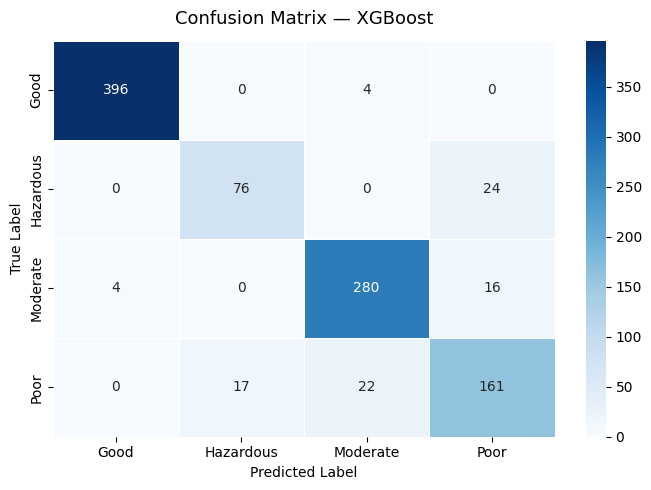

In [ ]:
ml_acc = accuracy_score(y_test, y_pred)
ml_f1  = f1_score(y_test, y_pred, average='weighted')

print("=== XGBOOST EVALUATION ===")
print(f"  Accuracy : {ml_acc:.4f}  ({ml_acc*100:.2f}%)")
print(f"  F1 Score : {ml_f1:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=le.classes_))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=le.classes_,
            yticklabels=le.classes_,
            cmap='Blues', linewidths=0.5, ax=ax)
ax.set_title('Confusion Matrix — XGBoost', fontsize=13, pad=12)
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
plt.tight_layout()
plt.show()

##2.8 Stratified K-Fold Cross Validation

=== STRATIFIED K-FOLD CROSS VALIDATION (K=5) ===

  Accuracy per fold : [np.float64(0.92), np.float64(0.922), np.float64(0.924), np.float64(0.935), np.float64(0.911)]
  Mean Accuracy     : 0.9224 ± 0.0077

  F1 per fold       : [np.float64(0.9199), np.float64(0.9216), np.float64(0.9233), np.float64(0.935), np.float64(0.9097)]
  Mean F1 Score     : 0.9219 ± 0.0081


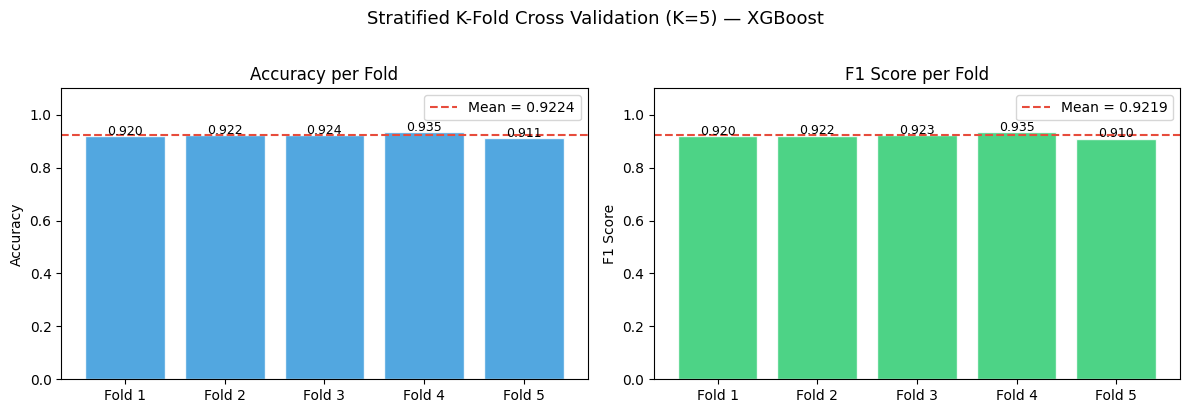


=== INTERPRETATION ===
  Low std  (±0.0077) → model is STABLE across different splits
  High mean (0.9224) → model GENERALISES well, not memorising


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_all = pd.concat([X_train_scaled, X_test_scaled], ignore_index=True)
y_all = np.concatenate([y_train, y_test])

cv_accuracy = cross_val_score(xgb_model, X_all, y_all,
                               cv=skf, scoring='accuracy', n_jobs=-1)
cv_f1       = cross_val_score(xgb_model, X_all, y_all,
                               cv=skf, scoring='f1_weighted', n_jobs=-1)

print("=== STRATIFIED K-FOLD CROSS VALIDATION (K=5) ===")
print(f"\n  Accuracy per fold : {[round(s, 4) for s in cv_accuracy]}")
print(f"  Mean Accuracy     : {cv_accuracy.mean():.4f} ± {cv_accuracy.std():.4f}")
print(f"\n  F1 per fold       : {[round(s, 4) for s in cv_f1]}")
print(f"  Mean F1 Score     : {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")

fold_labels = [f'Fold {i+1}' for i in range(5)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(fold_labels, cv_accuracy, color='#3498db', edgecolor='white', alpha=0.85)
axes[0].axhline(cv_accuracy.mean(), color='#e74c3c', linestyle='--',
                label=f'Mean = {cv_accuracy.mean():.4f}')
axes[0].set_title('Accuracy per Fold', fontsize=12)
axes[0].set_ylim(0, 1.1)
axes[0].set_ylabel('Accuracy')
axes[0].legend()
for i, v in enumerate(cv_accuracy):
    axes[0].text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=9)

axes[1].bar(fold_labels, cv_f1, color='#2ecc71', edgecolor='white', alpha=0.85)
axes[1].axhline(cv_f1.mean(), color='#e74c3c', linestyle='--',
                label=f'Mean = {cv_f1.mean():.4f}')
axes[1].set_title('F1 Score per Fold', fontsize=12)
axes[1].set_ylim(0, 1.1)
axes[1].set_ylabel('F1 Score')
axes[1].legend()
for i, v in enumerate(cv_f1):
    axes[1].text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=9)

plt.suptitle('Stratified K-Fold Cross Validation (K=5) — XGBoost', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"\n=== INTERPRETATION ===")
print(f"  Low std  (±{cv_accuracy.std():.4f}) → model is STABLE across different splits")
print(f"  High mean ({cv_accuracy.mean():.4f}) → model GENERALISES well, not memorising")

##2.9 Machine Learning vs Baseline Comparison

=== ML vs BASELINE COMPARISON ===
Metric           Baseline         XGBoost   Improvement
-------------------------------------------------------
Accuracy           0.4120          0.9130       +0.5010
F1 Score           0.2602          0.9126       +0.6524


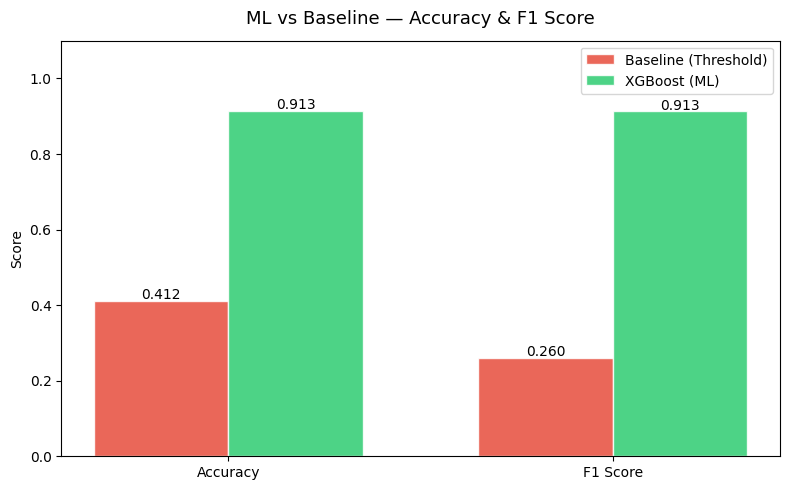


=== WHY ML IS BETTER THAN BASELINE ===
  ✓ Uses ALL 8 features, not just Pollution_Index
  ✓ Learns complex interactions between pollutants
  ✓ Not limited to fixed arbitrary threshold values
  ✓ Lower false alarm rate than rigid threshold rules
  ✓ Stable performance confirmed by K-Fold cross validation


In [ ]:
print("=== ML vs BASELINE COMPARISON ===")
print(f"{'Metric':12} {'Baseline':>12} {'XGBoost':>15} {'Improvement':>13}")
print("-" * 55)
print(f"{'Accuracy':12} {baseline_acc:>12.4f} {ml_acc:>15.4f} {(ml_acc - baseline_acc):>+13.4f}")
print(f"{'F1 Score':12} {baseline_f1:>12.4f} {ml_f1:>15.4f} {(ml_f1  - baseline_f1):>+13.4f}")

metrics         = ['Accuracy', 'F1 Score']
baseline_scores = [baseline_acc, baseline_f1]
ml_scores       = [ml_acc, ml_f1]

x     = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, baseline_scores, width,
               label='Baseline (Threshold)', color='#e74c3c', alpha=0.85, edgecolor='white')
bars2 = ax.bar(x + width/2, ml_scores,       width,
               label='XGBoost (ML)',          color='#2ecc71', alpha=0.85, edgecolor='white')

for bar in bars1 + bars2:
    ax.annotate(f'{bar.get_height():.3f}',
                (bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005),
                ha='center', fontsize=10)

ax.set_title('ML vs Baseline — Accuracy & F1 Score', fontsize=13, pad=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.legend()
plt.tight_layout()
plt.show()

print("\n=== WHY ML IS BETTER THAN BASELINE ===")
print("  ✓ Uses ALL 8 features, not just Pollution_Index")
print("  ✓ Learns complex interactions between pollutants")
print("  ✓ Not limited to fixed arbitrary threshold values")
print("  ✓ Lower false alarm rate than rigid threshold rules")
print("  ✓ Stable performance confirmed by K-Fold cross validation")

##2.10 Feature Importance

=== FEATURE IMPORTANCE RANKING ===
  1. CO                  : 0.6624 (66.2%)
  2. NO2                 : 0.0849 (8.5%)
  3. SO2                 : 0.0676 (6.8%)
  4. Temperature         : 0.0553 (5.5%)
  5. Humidity            : 0.0454 (4.5%)
  6. PM10                : 0.0315 (3.1%)
  7. Pollution_Index     : 0.0297 (3.0%)
  8. PM2.5               : 0.0231 (2.3%)


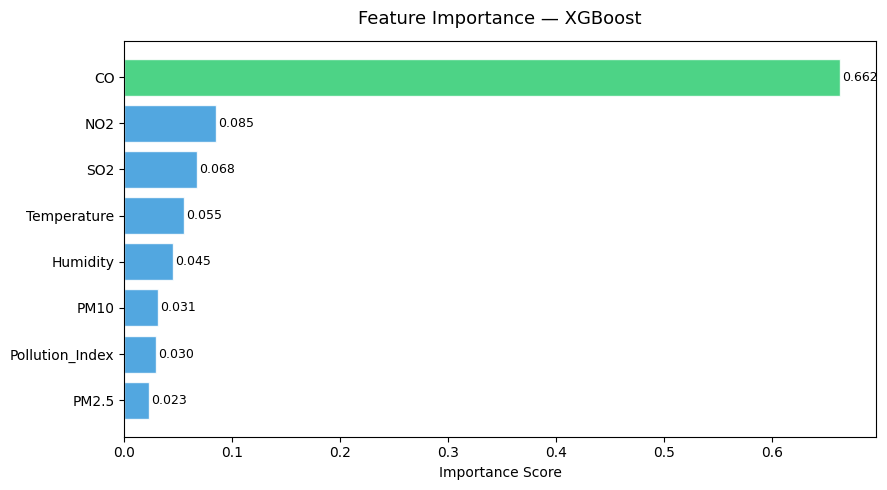


=== MODEL LIMITATIONS ===
  ⚠ Trained on static dataset — may not generalise to all cities/regions
  ⚠ No retraining mechanism if sensor drift occurs over time
  ⚠ XGBoost is not easily interpretable row-by-row (black box)
  ⚠ Prediction quality depends on quality of incoming sensor data


In [ ]:
importances = xgb_model.feature_importances_
indices     = np.argsort(importances)[::-1]

print("=== FEATURE IMPORTANCE RANKING ===")
for rank, i in enumerate(indices):
    print(f"  {rank+1}. {FEATURES[i]:20s}: {importances[i]:.4f} ({importances[i]*100:.1f}%)")

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#2ecc71' if importances[i] == max(importances)
          else '#3498db' for i in indices]

ax.barh([FEATURES[i] for i in indices[::-1]],
        [importances[i] for i in indices[::-1]],
        color=colors[::-1], edgecolor='white', alpha=0.85)

ax.set_title('Feature Importance — XGBoost', fontsize=13, pad=12)
ax.set_xlabel('Importance Score')
for i, v in enumerate([importances[j] for j in indices[::-1]]):
    ax.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print("\n=== MODEL LIMITATIONS ===")
print("  ⚠ Trained on static dataset — may not generalise to all cities/regions")
print("  ⚠ No retraining mechanism if sensor drift occurs over time")
print("  ⚠ XGBoost is not easily interpretable row-by-row (black box)")
print("  ⚠ Prediction quality depends on quality of incoming sensor data")

##2.11 Export Model

In [ ]:
joblib.dump(xgb_model, 'model.pkl')
joblib.dump(le,        'label_encoder.pkl')
joblib.dump(scaler,    'scaler.pkl')

print("=== MODEL FILES EXPORTED ===")
print("  ✓ model.pkl          → trained XGBoost classifier")
print("  ✓ label_encoder.pkl  → encodes Good/Moderate/Poor/Hazardous ↔ 0/1/2/3")
print("  ✓ scaler.pkl         → MinMaxScaler fitted on X_train only")
print("\nThese 3 files are required by the Flask API for Node-RED inference.")
print("\n=== SUMMARY ===")
print(f"  Baseline Accuracy  : {baseline_acc*100:.2f}%")
print(f"  XGBoost Accuracy   : {ml_acc*100:.2f}%")
print(f"  K-Fold Mean Acc    : {cv_accuracy.mean()*100:.2f}% ± {cv_accuracy.std()*100:.2f}%")
print(f"  Improvement        : +{(ml_acc - baseline_acc)*100:.2f}%")

try:
    from google.colab import files
    files.download('model.pkl')
    files.download('label_encoder.pkl')
    files.download('scaler.pkl')
    files.download('nodered_replay.csv')
    print("\n✓ All files downloading...")
except ImportError:
    print("\n(Not in Colab — files saved to current directory)")

=== MODEL FILES EXPORTED ===
  ✓ model.pkl          → trained XGBoost classifier
  ✓ label_encoder.pkl  → encodes Good/Moderate/Poor/Hazardous ↔ 0/1/2/3
  ✓ scaler.pkl         → MinMaxScaler fitted on X_train only

These 3 files are required by the Flask API for Node-RED inference.

=== SUMMARY ===
  Baseline Accuracy  : 41.20%
  XGBoost Accuracy   : 91.30%
  K-Fold Mean Acc    : 92.24% ± 0.77%
  Improvement        : +50.10%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ All files downloading...


#3.0 Deploy Model

##3.1 Install Flask & ngrok

In [ ]:
!pip install flask pyngrok

##3.2 Deploy Flask API with ngrok

In [ ]:
from flask import Flask, request, jsonify
from pyngrok import ngrok
import threading
import pandas as pd
import numpy as np

NGROK_TOKEN = "3DIypJT0v3beTgDwf4wflNoB7ei_75akkMqLpuDdHzwHieST1"


ngrok.set_auth_token(NGROK_TOKEN)

app = Flask(__name__)

FEATURES = ['Temperature', 'Humidity', 'PM2.5', 'PM10',
            'NO2', 'SO2', 'CO', 'Pollution_Index']

ALERT_MAP = {
    'Good':      {'alert': 'NORMAL',   'color': 'green',  'action': 'No action needed.'},
    'Moderate':  {'alert': 'CAUTION',  'color': 'yellow', 'action': 'Reduce outdoor activities.'},
    'Poor':      {'alert': 'WARNING',  'color': 'orange', 'action': 'Wear mask. Limit outdoor exposure.'},
    'Hazardous': {'alert': 'DANGER',   'color': 'red',    'action': 'Stay indoors. Activate air purifiers.'}
}

@app.route('/health', methods=['GET'])
def health():
    return jsonify({
        'status' : 'running',
        'model'  : 'XGBoost - Air Quality Classifier',
        'classes': list(le.classes_)
    })

@app.route('/predict', methods=['POST'])
def predict():
    try:
        data = request.get_json(force=True)

        missing_keys = [f for f in FEATURES if f not in data]
        if missing_keys:
            return jsonify({'error': f'Missing features: {missing_keys}'}), 400

        df_input = pd.DataFrame([data])[FEATURES]

        df_scaled = scaler.transform(df_input)

        pred_encoded   = xgb_model.predict(df_scaled)[0]
        pred_label     = le.inverse_transform([pred_encoded])[0]
        probabilities  = xgb_model.predict_proba(df_scaled)[0]
        confidence     = round(float(probabilities.max()), 3)

        prob_dict = {
            le.inverse_transform([i])[0]: round(float(p), 3)
            for i, p in enumerate(probabilities)
        }

        alert_info = ALERT_MAP.get(pred_label, {'alert': 'UNKNOWN', 'color': 'grey', 'action': 'N/A'})

        return jsonify({
            'prediction'    : pred_label,
            'confidence'    : confidence,
            'probabilities' : prob_dict,
            'alert'         : alert_info['alert'],
            'color'         : alert_info['color'],
            'recommendation': alert_info['action']
        })

    except Exception as e:
        return jsonify({'error': str(e)}), 500

def run_flask():
    app.run(port=5001, use_reloader=False, debug=False)

flask_thread = threading.Thread(target=run_flask, daemon=True)
flask_thread.start()

public_url = ngrok.connect(5001)
PREDICT_URL = public_url.public_url + "/predict"
HEALTH_URL  = public_url.public_url + "/health"

print("=" * 60)
print("  ✅  Flask API is LIVE!")
print(f"  🔗 Predict : {PREDICT_URL}")
print(f"  💚 Health  : {HEALTH_URL}")
print("=" * 60)
print("\n📌 Copy the Predict URL → paste into Node-RED HTTP request node")

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5001
INFO:werkzeug:Press CTRL+C to quit


  ✅  Flask API is LIVE!
  🔗 Predict : https://bubble-cure-deviator.ngrok-free.dev/predict
  💚 Health  : https://bubble-cure-deviator.ngrok-free.dev/health

📌 Copy the Predict URL → paste into Node-RED HTTP request node


##3.3 Test API Prediction

In [ ]:
import requests

# Simulated raw sensor reading (before scaling)
test_payload = {
    "Temperature"    : 35.2,
    "Humidity"       : 78.5,
    "PM2.5"          : 85.3,
    "PM10"           : 120.4,
    "NO2"            : 45.6,
    "SO2"            : 18.2,
    "CO"             : 9.1,
    "Pollution_Index": 68.7
}

response = requests.post(PREDICT_URL, json=test_payload)
result   = response.json()

print("=== TEST PREDICTION ===")
print(f"  Prediction     : {result['prediction']}")
print(f"  Confidence     : {result['confidence']*100:.1f}%")
print(f"  Alert          : {result['alert']}")
print(f"  Color          : {result['color']}")
print(f"  Recommendation : {result['recommendation']}")
print(f"\n  All probabilities:")
for cls, prob in result['probabilities'].items():
    print(f"    {cls:12s}: {prob*100:.1f}%")

INFO:werkzeug:127.0.0.1 - - [16/May/2026 04:19:42] "POST /predict HTTP/1.1" 200 -


=== TEST PREDICTION ===
  Prediction     : Hazardous
  Confidence     : 99.6%
  Alert          : DANGER
  Color          : red
  Recommendation : Stay indoors. Activate air purifiers.

  All probabilities:
    Good        : 0.0%
    Hazardous   : 99.6%
    Moderate    : 0.0%
    Poor        : 0.4%


#3.4 : Export Raw + Normalized Together

In [ ]:
# Export enriched replay file with both raw and normalized columns
df_raw = df_clean.copy()  # raw cleaned values (before normalization)

# Add normalized Pollution_Index from df_final
df_raw['Pollution_Index'] = df_final['Pollution_Index']

# Add normalized versions for ML (what Flask uses)
for col in ['Temperature','Humidity','PM2.5','PM10','NO2','SO2','CO','Pollution_Index']:
    df_raw[f'{col}_norm'] = df_final[col]

# Save first 500 rows
df_raw.iloc[:500].to_csv('nodered_replay_v2.csv', index=False)

from google.colab import files
files.download('nodered_replay_v2.csv')
print("✓ nodered_replay_v2.csv downloaded")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ nodered_replay_v2.csv downloaded
